# Data Preparation

In [396]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tslearn.preprocessing import TimeSeriesScalerMeanVariance

In [397]:
df = pd.read_csv('src\\wdi_raw.csv')

## WDI

In [398]:
df.columns

Index(['economy', 'series', 'Country', 'Series', 'YR1960', 'YR1961', 'YR1962',
       'YR1963', 'YR1964', 'YR1965', 'YR1966', 'YR1967', 'YR1968', 'YR1969',
       'YR1970', 'YR1971', 'YR1972', 'YR1973', 'YR1974', 'YR1975', 'YR1976',
       'YR1977', 'YR1978', 'YR1979', 'YR1980', 'YR1981', 'YR1982', 'YR1983',
       'YR1984', 'YR1985', 'YR1986', 'YR1987', 'YR1988', 'YR1989', 'YR1990',
       'YR1991', 'YR1992', 'YR1993', 'YR1994', 'YR1995', 'YR1996', 'YR1997',
       'YR1998', 'YR1999', 'YR2000', 'YR2001', 'YR2002', 'YR2003', 'YR2004',
       'YR2005', 'YR2006', 'YR2007', 'YR2008', 'YR2009', 'YR2010', 'YR2011',
       'YR2012', 'YR2013', 'YR2014', 'YR2015', 'YR2016', 'YR2017', 'YR2018',
       'YR2019', 'YR2020', 'YR2021', 'YR2022', 'YR2023', 'YR2024', 'YR2025'],
      dtype='str')

In [399]:
df['Series'].unique()

<ArrowStringArray>
[               'Energy intensity level of primary energy (MJ/$2021 PPP GDP)',
 'Total greenhouse gas emissions excluding LULUCF per capita (t CO2e/capita)',
             'Carbon intensity of GDP (kg CO2e per constant 2015 US$ of GDP)',
         'Renewable energy consumption (% of total final energy consumption)',
                               'Energy use (kg of oil equivalent per capita)',
                                         'GDP per capita (constant 2015 US$)']
Length: 6, dtype: str

In [400]:
df = df.drop(columns = 'series')

### Removing group of countries 

In [401]:
countries = df['Country'].unique()
print(list(countries))

['Zimbabwe', 'Zambia', 'Yemen, Rep.', 'West Bank and Gaza', 'Virgin Islands (U.S.)', 'Viet Nam', 'Venezuela, RB', 'Vanuatu', 'Uzbekistan', 'Uruguay', 'United States', 'United Kingdom', 'United Arab Emirates', 'Ukraine', 'Uganda', 'Tuvalu', 'Turks and Caicos Islands', 'Turkmenistan', 'Turkiye', 'Tunisia', 'Trinidad and Tobago', 'Tonga', 'Togo', 'Timor-Leste', 'Thailand', 'Tanzania', 'Tajikistan', 'Syrian Arab Republic', 'Switzerland', 'Sweden', 'Suriname', 'Sudan', 'St. Vincent and the Grenadines', 'St. Martin (French part)', 'St. Lucia', 'St. Kitts and Nevis', 'Sri Lanka', 'Spain', 'South Sudan', 'South Africa', 'Somalia, Fed. Rep.', 'Solomon Islands', 'Slovenia', 'Slovak Republic', 'Sint Maarten (Dutch part)', 'Singapore', 'Sierra Leone', 'Seychelles', 'Serbia', 'Senegal', 'Saudi Arabia', 'Sao Tome and Principe', 'San Marino', 'Samoa', 'Rwanda', 'Russian Federation', 'Romania', 'Qatar', 'Puerto Rico (US)', 'Portugal', 'Poland', 'Philippines', 'Peru', 'Paraguay', 'Papua New Guinea', 'P

In [402]:
len(df['Country'].unique())

266

In [403]:
countries = pd.read_csv('src\\countries.csv') 

In [404]:
df = df[df['Country'].isin(countries['name'])]

In [405]:
df['Country'].unique()

<ArrowStringArray>
[             'Zimbabwe',                'Zambia',           'Yemen, Rep.',
    'West Bank and Gaza', 'Virgin Islands (U.S.)',              'Viet Nam',
         'Venezuela, RB',               'Vanuatu',            'Uzbekistan',
               'Uruguay',
 ...
                 'Aruba',               'Armenia',             'Argentina',
   'Antigua and Barbuda',                'Angola',               'Andorra',
        'American Samoa',               'Algeria',               'Albania',
           'Afghanistan']
Length: 217, dtype: str

### Transformation into long type

In [406]:
id_cols = ['economy', 'Series', 'Country']
year_cols = [col for col in df.columns if col.startswith('YR')]

In [407]:
df = df.melt(
    id_vars=id_cols,
    value_vars=year_cols,
    var_name='year',
    value_name='value'
)

### Nans

In [408]:
(df['value'] == 0).groupby(df['Series']).sum()


Series
Carbon intensity of GDP (kg CO2e per constant 2015 US$ of GDP)                122
Energy intensity level of primary energy (MJ/$2021 PPP GDP)                     0
Energy use (kg of oil equivalent per capita)                                    1
GDP per capita (constant 2015 US$)                                              0
Renewable energy consumption (% of total final energy consumption)            410
Total greenhouse gas emissions excluding LULUCF per capita (t CO2e/capita)      0
Name: value, dtype: int64

In [409]:
year_completeness = df.groupby( ['year','Series'])['value'].apply(
    lambda x: x.notna().mean() * 100
)


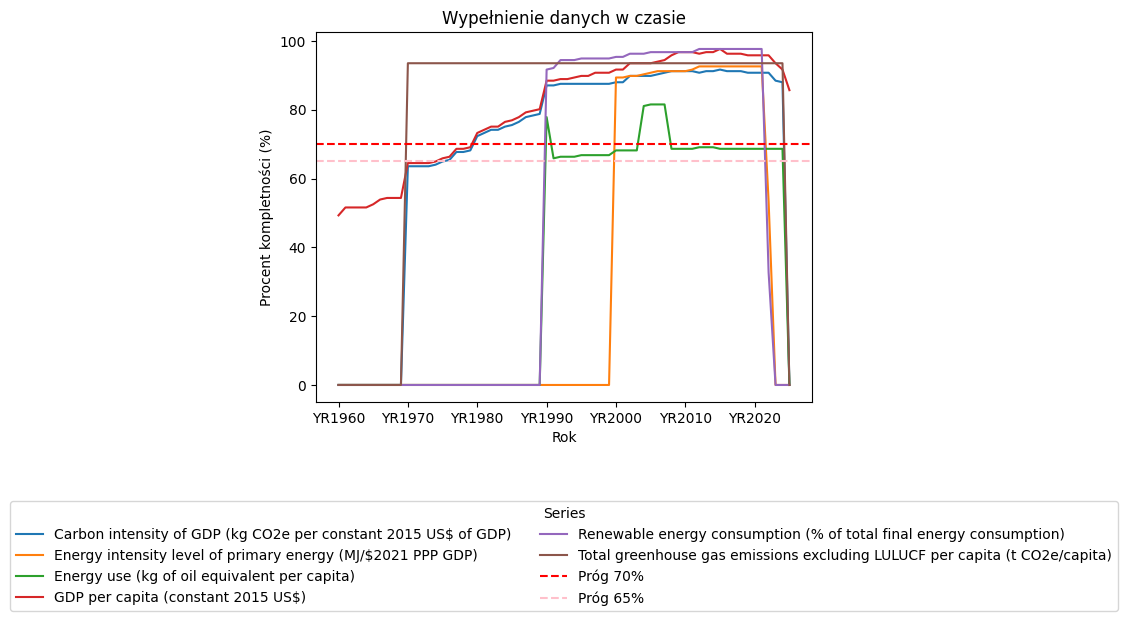

In [410]:
year_completeness.unstack().plot()
plt.title("Wypełnienie danych w czasie")
plt.ylabel("Procent kompletności (%)")
plt.xlabel("Rok")
plt.axhline(y=70, color='red', linestyle='--', linewidth=1.5, label='Próg 70%')
plt.axhline(y=65, color='pink', linestyle='--', linewidth=1.5, label='Próg 65%')
plt.legend(title="Series", loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2)
plt.show()

In [411]:
df = df[df['Series'] != 'Energy intensity of GDP (kg CO2e per constant 2015 US$ of GDP)']

In [412]:
ENERGY_INT_WDI = 'Energy intensity level of primary energy (MJ/$2021 PPP GDP)'
EN_PC  = 'Energy use (kg of oil equivalent per capita)'
GDP_PC = 'GDP per capita (constant 2015 US$)'
NEW    = 'Energy intensity (kg oe per constant 2015 US$ GDP) [derived]'

df_all = df[df['Series'] != ENERGY_INT_WDI].copy()

w = df_all.pivot(index=['economy', 'Country', 'year'], columns='Series', values='value')
derived = (w[EN_PC] / w[GDP_PC]).rename('value').reset_index()
derived['Series'] = NEW
df = pd.concat([df_all, derived[df_all.columns]], ignore_index=True)

In [413]:
year_completeness.unstack('Series').loc['YR2015':'YR2025']

Series,Carbon intensity of GDP (kg CO2e per constant 2015 US$ of GDP),Energy intensity level of primary energy (MJ/$2021 PPP GDP),Energy use (kg of oil equivalent per capita),GDP per capita (constant 2015 US$),Renewable energy consumption (% of total final energy consumption),Total greenhouse gas emissions excluding LULUCF per capita (t CO2e/capita)
year,,,,,,
YR2015,91.705069,92.626728,68.663594,97.695853,97.695853,93.548387
YR2016,91.244240,92.626728,68.663594,96.313364,97.695853,93.548387
YR2017,91.244240,92.626728,68.663594,96.313364,97.695853,93.548387
YR2018,91.244240,92.626728,68.663594,96.313364,97.695853,93.548387
YR2019,90.783410,92.626728,68.663594,95.852535,97.695853,93.548387
YR2020,90.783410,92.626728,68.663594,95.852535,97.695853,93.548387
YR2021,90.783410,92.626728,68.663594,95.852535,97.695853,93.548387
YR2022,90.783410,53.456221,68.663594,95.852535,32.718894,93.548387
YR2023,88.479263,0.000000,68.663594,93.548387,0.000000,93.548387


In [414]:
df.year = df.year.str.replace('YR', ' ')
df['year'] = df['year'].astype(int)

In [415]:
df = df[(df['year'] >=1990) & (df['year'] <= 2021) ]

In [416]:
df.year.max()

np.int64(2021)

In [417]:
country_completeness = df.groupby(['Country', 'Series'])['value'].apply(
    lambda x: x.notna().mean() * 100
)

In [418]:
country_completeness

Country      Series                                                                    
Afghanistan  Carbon intensity of GDP (kg CO2e per constant 2015 US$ of GDP)                 68.75
             Energy intensity (kg oe per constant 2015 US$ GDP) [derived]                    0.00
             Energy use (kg of oil equivalent per capita)                                    0.00
             GDP per capita (constant 2015 US$)                                             68.75
             Renewable energy consumption (% of total final energy consumption)            100.00
                                                                                            ...  
Zimbabwe     Energy intensity (kg oe per constant 2015 US$ GDP) [derived]                  100.00
             Energy use (kg of oil equivalent per capita)                                  100.00
             GDP per capita (constant 2015 US$)                                            100.00
             Renewable energy 

In [419]:
n_indicators = df['Series'].nunique()  # 7

energy_ok = country_completeness[
    (country_completeness.index.get_level_values('Series') == 'Energy use (kg of oil equivalent per capita)') &
    (country_completeness >= 65)
].index.get_level_values('Country')


other_ok = country_completeness[
    country_completeness.index.get_level_values('Series') != 'Energy use (kg of oil equivalent per capita)'
]
other_passed_count = (other_ok >= 70).groupby(other_ok.index.get_level_values('Country')).sum()
other_ok_countries = other_passed_count[other_passed_count == n_indicators - 1].index


good_countries = set(energy_ok) & set(other_ok_countries)

len(good_countries)

140

In [420]:
df = df[df['Country'].isin(good_countries)]

In [421]:
df.value.describe()

count     26855.000000
mean       2632.303977
std        8955.203335
min           0.000000
25%           0.502932
50%           8.800000
75%         866.290578
max      112422.146494
Name: value, dtype: float64

In [422]:
(df['value'] == 0).groupby(df['Series']).sum()

Series
Carbon intensity of GDP (kg CO2e per constant 2015 US$ of GDP)                  0
Energy intensity (kg oe per constant 2015 US$ GDP) [derived]                    1
Energy use (kg of oil equivalent per capita)                                    1
GDP per capita (constant 2015 US$)                                              0
Renewable energy consumption (% of total final energy consumption)            180
Total greenhouse gas emissions excluding LULUCF per capita (t CO2e/capita)      0
Name: value, dtype: int64

In [423]:
renewable_0 = df[(df['Series']=='Renewable energy consumption (% of total final energy consumption)') & (df['value']==0)][['Country','year']]
renewable_0.to_csv('temp\\renewable_0.csv')

In [424]:
df[(df['Series']=='Renewable energy consumption (% of total final energy consumption)') & (df['value']==0)][['Country','year']].drop_duplicates('Country')

,Country,year
32996,United Arab Emirates,1990
33001,Turkmenistan,1990
33034,Saudi Arabia,1990
33052,Oman,1990
33077,Malta,1990
33186,Bahrain,1990
36296,Qatar,1993
36427,Brunei Darussalam,1993
37434,Kuwait,1994
43964,"Hong Kong SAR, China",2000


In [425]:
df[(df['Series']=='Energy use (kg of oil equivalent per capita)') & (df['value']==0)][['Country','year']]

,Country,year
33281,Namibia,1990


In [426]:
mask = (
    (df['economy'] == 'NAM') &
    (df['Series'] == 'Renewable energy consumption (% of total final energy consumption)') &
    (df['year'] == 1990) 
)
df.loc[mask, 'value'] = 0

In [427]:
df[df['value'].isna()].groupby('Series').size()

Series
Carbon intensity of GDP (kg CO2e per constant 2015 US$ of GDP)        3
Energy intensity (kg oe per constant 2015 US$ GDP) [derived]          8
Energy use (kg of oil equivalent per capita)                          5
GDP per capita (constant 2015 US$)                                    3
Renewable energy consumption (% of total final energy consumption)    5
dtype: int64

In [428]:
df[df['value'].isna()]

,economy,Series,Country,year,value
33167,KHM,Renewable energy consumption (% of total final...,Cambodia,1990,NaN
33384,KHM,Energy use (kg of oil equivalent per capita),Cambodia,1990,NaN
34252,KHM,Renewable energy consumption (% of total final...,Cambodia,1991,NaN
34469,KHM,Energy use (kg of oil equivalent per capita),Cambodia,1991,NaN
35337,KHM,Renewable energy consumption (% of total final...,Cambodia,1992,NaN
35554,KHM,Energy use (kg of oil equivalent per capita),Cambodia,1992,NaN
36422,KHM,Renewable energy consumption (% of total final...,Cambodia,1993,NaN
36639,KHM,Energy use (kg of oil equivalent per capita),Cambodia,1993,NaN
37507,KHM,Renewable energy consumption (% of total final...,Cambodia,1994,NaN
37724,KHM,Energy use (kg of oil equivalent per capita),Cambodia,1994,NaN


In [429]:
df[(df['value'].isna()) & (df['economy'] == 'YEM')]

,economy,Series,Country,year,value
64234,YEM,Carbon intensity of GDP (kg CO2e per constant ...,"Yemen, Rep.",2019,NaN
64885,YEM,GDP per capita (constant 2015 US$),"Yemen, Rep.",2019,NaN
65319,YEM,Carbon intensity of GDP (kg CO2e per constant ...,"Yemen, Rep.",2020,NaN
65970,YEM,GDP per capita (constant 2015 US$),"Yemen, Rep.",2020,NaN
66404,YEM,Carbon intensity of GDP (kg CO2e per constant ...,"Yemen, Rep.",2021,NaN
67055,YEM,GDP per capita (constant 2015 US$),"Yemen, Rep.",2021,NaN
85727,YEM,Energy intensity (kg oe per constant 2015 US$ ...,"Yemen, Rep.",2019,NaN
85728,YEM,Energy intensity (kg oe per constant 2015 US$ ...,"Yemen, Rep.",2020,NaN
85729,YEM,Energy intensity (kg oe per constant 2015 US$ ...,"Yemen, Rep.",2021,NaN


In [430]:
df[(df['value'].isna()) & (df['economy'] == 'KHM')]

,economy,Series,Country,year,value
33167,KHM,Renewable energy consumption (% of total final...,Cambodia,1990,NaN
33384,KHM,Energy use (kg of oil equivalent per capita),Cambodia,1990,NaN
34252,KHM,Renewable energy consumption (% of total final...,Cambodia,1991,NaN
34469,KHM,Energy use (kg of oil equivalent per capita),Cambodia,1991,NaN
35337,KHM,Renewable energy consumption (% of total final...,Cambodia,1992,NaN
35554,KHM,Energy use (kg of oil equivalent per capita),Cambodia,1992,NaN
36422,KHM,Renewable energy consumption (% of total final...,Cambodia,1993,NaN
36639,KHM,Energy use (kg of oil equivalent per capita),Cambodia,1993,NaN
37507,KHM,Renewable energy consumption (% of total final...,Cambodia,1994,NaN
37724,KHM,Energy use (kg of oil equivalent per capita),Cambodia,1994,NaN


In [431]:
countries_to_drop = ['KHM',  'YEM']
df = df[~df['economy'].isin(countries_to_drop)]

In [432]:
df.value.describe()

count     26496.000000
mean       2663.868993
std        9011.268116
min           0.000000
25%           0.504970
50%           8.900000
75%         883.960079
max      112422.146494
Name: value, dtype: float64

In [433]:
df[df['value'].isna()]

,economy,Series,Country,year,value


In [434]:
df['Country'].nunique()

138

In [435]:
import plotly.express as px


final_countries = df[['economy', 'Country']].drop_duplicates()

fig = px.choropleth(
    final_countries,
    locations='economy',          
    color=[1] * len(final_countries),   #
    hover_name='Country',
    color_continuous_scale=["#25df0c", "#a3b82c"],  # nwm  czemu dziala tylko jak sie poda dw kolory
    title='Kraje uwzględnione w analizie (n=138)'
)

fig.update_layout(
    coloraxis_showscale=False,
    width=1600,   
    height=900,   
    title_font_size=20
)
fig.update_layout(coloraxis_showscale=False)
fig.show()


fig.write_html('attachments/Countries.html')


### Z-Score

In [436]:
df['value_scaled'] = df.groupby(['Country', 'Series'])['value'].transform(
    lambda x: (x - x.mean()) / x.std()
)

### Normalizacja szeregów

In [437]:
lengths = df.groupby(['Country', 'Series']).size()
lengths.unique()

array([32])

In [438]:
pivot = df.pivot_table(
    index='Country',
    columns=['Series', 'year'],
    values='value_scaled'
)

In [439]:
pivot.isna().sum().sum()

np.int64(32)

In [440]:
zero_std = df.groupby(['Country', 'Series'])['value'].std()
zero_std[zero_std == 0]

Country  Series                                                            
Bahrain  Renewable energy consumption (% of total final energy consumption)    0.0
Name: value, dtype: float64

In [441]:
def safe_zscore(x):
    std = x.std()
    return (x - x.mean()) / std if std != 0 else x - x.mean()

df['value_scaled'] = df.groupby(['Country', 'Series'])['value'].transform(safe_zscore)

In [442]:
pivot = df.pivot_table(
    index='Country',
    columns=['Series', 'year'],
    values='value_scaled'
)

In [443]:
pivot.isna().sum().sum()

np.int64(0)

In [444]:
df.to_csv('modified_data\\wdi.csv')

# EUROSTAT

### Preparation of Demography dataset

In [445]:
df_demo = pd.read_csv("src/estat_demo_pjan.tsv", sep ="\t")

In [446]:
df_demo.columns

Index(['freq,unit,age,sex,geo\TIME_PERIOD', '1960 ', '1961 ', '1962 ', '1963 ',
       '1964 ', '1965 ', '1966 ', '1967 ', '1968 ', '1969 ', '1970 ', '1971 ',
       '1972 ', '1973 ', '1974 ', '1975 ', '1976 ', '1977 ', '1978 ', '1979 ',
       '1980 ', '1981 ', '1982 ', '1983 ', '1984 ', '1985 ', '1986 ', '1987 ',
       '1988 ', '1989 ', '1990 ', '1991 ', '1992 ', '1993 ', '1994 ', '1995 ',
       '1996 ', '1997 ', '1998 ', '1999 ', '2000 ', '2001 ', '2002 ', '2003 ',
       '2004 ', '2005 ', '2006 ', '2007 ', '2008 ', '2009 ', '2010 ', '2011 ',
       '2012 ', '2013 ', '2014 ', '2015 ', '2016 ', '2017 ', '2018 ', '2019 ',
       '2020 ', '2021 ', '2022 ', '2023 ', '2024 ', '2025 '],
      dtype='str')

In [447]:
first_col = df_demo.columns[0]

In [448]:
new_col = first_col.split(",")
df_demo[new_col] = df_demo[first_col].str.split(",", expand=True)

In [449]:
df_demo  = df_demo.drop(columns= first_col)

In [450]:
df_demo.insert(0, 'Freq',df_demo['freq'])
df_demo.insert(1, 'Unit',df_demo['unit'])
df_demo.insert(2, 'Age',df_demo['age'])
df_demo.insert(3, 'Sex',df_demo['sex'])
df_demo.insert(4, 'Geo\\time',df_demo['geo\\TIME_PERIOD'])

In [451]:
df_demo

,Freq,Unit,Age,Sex,Geo\time,1960,1961,1962,1963,1964,...,2021,2022,2023,2024,2025,freq,unit,age,sex,geo\TIME_PERIOD
0,A,NR,TOTAL,F,AD,:,:,:,:,:,...,:,:,:,:,:,A,NR,TOTAL,F,AD
1,A,NR,TOTAL,F,AL,:,:,:,:,:,...,1419759,1406532,1394864,:,1194597,A,NR,TOTAL,F,AL
2,A,NR,TOTAL,F,AM,:,:,:,:,:,...,1565144,:,1571757,1577675,:,A,NR,TOTAL,F,AM
3,A,NR,TOTAL,F,AT,3757167,3773097,3794130,3814191,3836415,...,4535712,4553444,4619957,4643918,4664333,A,NR,TOTAL,F,AT
4,A,NR,TOTAL,F,AZ,:,:,:,:,:,...,5065288,5081846,5087516,5113564,5135511,A,NR,TOTAL,F,AZ
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17740,A,NR,Y_OPEN,T,SM,:,:,:,:,:,...,:,:,:,:,:,A,NR,Y_OPEN,T,SM
17741,A,NR,Y_OPEN,T,TR,61869,63574,65335,67153,69029,...,5780,:,6247,6609,7632,A,NR,Y_OPEN,T,TR
17742,A,NR,Y_OPEN,T,UA,:,:,:,:,:,...,18720,24000,:,:,:,A,NR,Y_OPEN,T,UA
17743,A,NR,Y_OPEN,T,UK,300000,300000,400000,400000,400000,...,:,:,:,:,:,A,NR,Y_OPEN,T,UK


In [452]:
old_col = df_demo[['freq','unit','age','sex','geo\\TIME_PERIOD']]

In [453]:
old_col

,freq,unit,age,sex,geo\TIME_PERIOD
0,A,NR,TOTAL,F,AD
1,A,NR,TOTAL,F,AL
2,A,NR,TOTAL,F,AM
3,A,NR,TOTAL,F,AT
4,A,NR,TOTAL,F,AZ
...,...,...,...,...,...
17740,A,NR,Y_OPEN,T,SM
17741,A,NR,Y_OPEN,T,TR
17742,A,NR,Y_OPEN,T,UA
17743,A,NR,Y_OPEN,T,UK


In [454]:
df_demo = df_demo.drop(columns = old_col)

In [455]:
df_demo

,Freq,Unit,Age,Sex,Geo\time,1960,1961,1962,1963,1964,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,A,NR,TOTAL,F,AD,:,:,:,:,:,...,:,:,:,37388,:,:,:,:,:,:
1,A,NR,TOTAL,F,AL,:,:,:,:,:,...,1417141,1423050,1431715,1432833,1425342,1419759,1406532,1394864,:,1194597
2,A,NR,TOTAL,F,AM,:,:,:,:,:,...,1569535,1567380,1564533,1563538,1562689,1565144,:,1571757,1577675,:
3,A,NR,TOTAL,F,AT,3757167,3773097,3794130,3814191,3836415,...,4427918,4460424,4483749,4501742,4522292,4535712,4553444,4619957,4643918,4664333
4,A,NR,TOTAL,F,AZ,:,:,:,:,:,...,4870002,4918771,4960058,4999053,5039100,5065288,5081846,5087516,5113564,5135511
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17740,A,NR,Y_OPEN,T,SM,:,:,:,:,:,...,:,:,8,:,:,:,:,:,:,:
17741,A,NR,Y_OPEN,T,TR,61869,63574,65335,67153,69029,...,127986,145341,5416,174875,5567,5780,:,6247,6609,7632
17742,A,NR,Y_OPEN,T,UA,:,:,:,:,:,...,6482,6839,8523,10365,11193,18720,24000,:,:,:
17743,A,NR,Y_OPEN,T,UK,300000,300000,400000,400000,400000,...,14407,14589,14469,13322,:,:,:,:,:,:


To long format

In [456]:
df_demo.columns

Index(['Freq', 'Unit', 'Age', 'Sex', 'Geo\time', '1960 ', '1961 ', '1962 ',
       '1963 ', '1964 ', '1965 ', '1966 ', '1967 ', '1968 ', '1969 ', '1970 ',
       '1971 ', '1972 ', '1973 ', '1974 ', '1975 ', '1976 ', '1977 ', '1978 ',
       '1979 ', '1980 ', '1981 ', '1982 ', '1983 ', '1984 ', '1985 ', '1986 ',
       '1987 ', '1988 ', '1989 ', '1990 ', '1991 ', '1992 ', '1993 ', '1994 ',
       '1995 ', '1996 ', '1997 ', '1998 ', '1999 ', '2000 ', '2001 ', '2002 ',
       '2003 ', '2004 ', '2005 ', '2006 ', '2007 ', '2008 ', '2009 ', '2010 ',
       '2011 ', '2012 ', '2013 ', '2014 ', '2015 ', '2016 ', '2017 ', '2018 ',
       '2019 ', '2020 ', '2021 ', '2022 ', '2023 ', '2024 ', '2025 '],
      dtype='str')

In [457]:
id_cols = ['Freq', 'Unit', 'Age', 'Sex', 'Geo\\time']
year_cols = [col for col in df_demo.columns if col.startswith(('19','20'))]
df_demo = df_demo.melt(
    id_vars=id_cols,
    value_vars=year_cols,
    var_name='year',
    value_name='value'
)

In [458]:
df_demo

,Freq,Unit,Age,Sex,Geo\time,year,value
0,A,NR,TOTAL,F,AD,1960,:
1,A,NR,TOTAL,F,AL,1960,:
2,A,NR,TOTAL,F,AM,1960,:
3,A,NR,TOTAL,F,AT,1960,3757167
4,A,NR,TOTAL,F,AZ,1960,:
...,...,...,...,...,...,...,...
1171165,A,NR,Y_OPEN,T,SM,2025,:
1171166,A,NR,Y_OPEN,T,TR,2025,7632
1171167,A,NR,Y_OPEN,T,UA,2025,:
1171168,A,NR,Y_OPEN,T,UK,2025,:


In [459]:
df_demo.year = df_demo.year.astype(int)

In [460]:
df_demo = df_demo[(df_demo['year'] >=1990) & (df_demo['year'] <= 2021) ]

In [461]:
df_demo

,Freq,Unit,Age,Sex,Geo\time,year,value
532350,A,NR,TOTAL,F,AD,1990,24171
532351,A,NR,TOTAL,F,AL,1990,:
532352,A,NR,TOTAL,F,AM,1990,:
532353,A,NR,TOTAL,F,AT,1990,3989903
532354,A,NR,TOTAL,F,AZ,1990,:
...,...,...,...,...,...,...,...
1100185,A,NR,Y_OPEN,T,SM,2021,:
1100186,A,NR,Y_OPEN,T,TR,2021,5780
1100187,A,NR,Y_OPEN,T,UA,2021,18720
1100188,A,NR,Y_OPEN,T,UK,2021,:


Nans

In [462]:
df_demo.value.isna().sum()

np.int64(0)

In [463]:
df_demo.value = df_demo.value.str.strip().replace(":", np.nan )

In [464]:
df_demo

,Freq,Unit,Age,Sex,Geo\time,year,value
532350,A,NR,TOTAL,F,AD,1990,24171
532351,A,NR,TOTAL,F,AL,1990,NaN
532352,A,NR,TOTAL,F,AM,1990,NaN
532353,A,NR,TOTAL,F,AT,1990,3989903
532354,A,NR,TOTAL,F,AZ,1990,NaN
...,...,...,...,...,...,...,...
1100185,A,NR,Y_OPEN,T,SM,2021,NaN
1100186,A,NR,Y_OPEN,T,TR,2021,5780
1100187,A,NR,Y_OPEN,T,UA,2021,18720
1100188,A,NR,Y_OPEN,T,UK,2021,NaN


In [465]:
df_demo.value.unique()

<ArrowStringArray>
[     '24171',          nan,    '3989903',    '5087683',    '4443535',
    '3416313',     '287064',    '5326444',   '32442597',   '41003093',
 ...
  '26210 bep',     '6696 e',    '894 bep',     '1962 e',      '619 b',
      '92586', '120291 bep',    '22186 e',   '4183 bep',     '6591 e']
Length: 211696, dtype: str

In [466]:
df_demo.value = df_demo.value.astype(str)

In [467]:
df_demo.value.dtype

<StringDtype(na_value=nan)>

In [468]:
ok = df_demo.value.str.split( ' ',expand = True)

In [469]:
value = ok[0]

In [470]:
value_expend = ok[1]

In [471]:
df_demo.value = value

In [472]:
df_demo.value[df_demo.value == 0].sum()

''

In [473]:
df_demo['Geo\\time'].unique()

<ArrowStringArray>
[        'AD',         'AL',         'AM',         'AT',         'AZ',
         'BA',         'BE',         'BG',         'BY',         'CH',
         'CY',         'CZ',         'DE',     'DE_TOT',         'DK',
       'EA20',       'EA21',         'EE', 'EEA30_2007',      'EEA31',
       'EFTA',         'EL',         'ES',  'EU27_2007',  'EU27_2020',
       'EU28',         'FI',         'FR',         'FX',         'GE',
         'HR',         'HU',         'IE',         'IS',         'IT',
         'LI',         'LT',         'LU',         'LV',         'MC',
         'MD',         'ME',         'MK',         'MT',         'NL',
         'NO',         'PL',         'PT',         'RO',         'RS',
         'RU',         'SE',         'SI',         'SK',         'SM',
         'TR',         'UA',         'UK',         'XK']
Length: 59, dtype: str

Stop here, i dont know if i need that